<a href="https://colab.research.google.com/github/HittersLab/Case-Exercises-Subsea-Integrity-Predictive-Analytics/blob/main/Case3_FMECA_Feature_Mapping/Case3_FMECA_Feature_Mapping.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Case Exercise 3: FMECA and Feature Mapping

## Question 1: Failure Modes, Effects and Criticality Analysis (FMECA)

### Objective
Develop an FMECA worksheet for a subsea Christmas tree with at least ten potential failure modes.

### Engineering Principle
FMECA systematically identifies how equipment can fail, the possible causes and consequences, and the controls used to detect or mitigate those failures.

A Risk Priority Number (RPN) is calculated using:

\[
RPN=S\times O\times D
\]

Where:
- S = severity score.
- O = occurrence likelihood score.
- D = difficulty of detection score.

For this exercise, each score uses a 1–10 scale. Higher scores represent greater severity, higher occurrence likelihood, or more difficult detection.

RPN supports prioritisation but should not replace engineering judgement. Different failure modes can produce the same RPN despite having very different consequences.


In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

OUTPUT_DIR = Path("data")
OUTPUT_DIR.mkdir(exist_ok=True)

fmeca_records = [
    {
        "component": "Production master valve",
        "failure_mode": "Fails to close",
        "effect": "Unable to isolate production flow",
        "cause": "Actuator or seat damage",
        "severity": 10, "occurrence": 3, "detection": 7,
        "physics_parameters": "Valve position, actuator pressure, flow rate",
        "ml_features": "Position deviation, closure time, actuator pressure trend",
        "mitigation": "Functional testing and actuator maintenance"
    },
    {
        "component": "Production wing valve",
        "failure_mode": "Internal leakage",
        "effect": "Loss of isolation",
        "cause": "Seat wear or debris",
        "severity": 8, "occurrence": 4, "detection": 6,
        "physics_parameters": "Upstream/downstream pressure, valve position",
        "ml_features": "Pressure differential during closed state, leakage residual",
        "mitigation": "Leak testing and valve inspection"
    },
    {
        "component": "Annulus valve",
        "failure_mode": "Fails to open",
        "effect": "Annulus access unavailable",
        "cause": "Actuator or mechanical seizure",
        "severity": 7, "occurrence": 4, "detection": 5,
        "physics_parameters": "Actuator pressure, position feedback",
        "ml_features": "Command-response delay, actuation pressure deviation",
        "mitigation": "Periodic function testing"
    },
    {
        "component": "Choke valve",
        "failure_mode": "Erosion or excessive wear",
        "effect": "Unstable flow and loss of control",
        "cause": "High-velocity multiphase flow",
        "severity": 8, "occurrence": 6, "detection": 6,
        "physics_parameters": "Flow rate, pressure drop, choke position",
        "ml_features": "Pressure-drop residual, flow-position relationship",
        "mitigation": "Monitor erosion indicators and inspect trim"
    },
    {
        "component": "Tree connector",
        "failure_mode": "Seal leakage",
        "effect": "Hydrocarbon release or loss of containment",
        "cause": "Seal degradation or installation damage",
        "severity": 10, "occurrence": 2, "detection": 8,
        "physics_parameters": "Pressure, temperature, leakage indicators",
        "ml_features": "Pressure-decay trend, anomaly score",
        "mitigation": "Qualified sealing procedures and pressure testing"
    },
    {
        "component": "Pressure sensor",
        "failure_mode": "Biased or drifting reading",
        "effect": "Incorrect operating assessment",
        "cause": "Sensor ageing or calibration drift",
        "severity": 7, "occurrence": 5, "detection": 6,
        "physics_parameters": "Pressure, redundant sensor readings",
        "ml_features": "Sensor disagreement, drift rate, residual",
        "mitigation": "Calibration and redundant measurement checks"
    },
    {
        "component": "Temperature sensor",
        "failure_mode": "Sensor failure",
        "effect": "Temperature excursions may go undetected",
        "cause": "Electrical or sensing-element fault",
        "severity": 6, "occurrence": 4, "detection": 5,
        "physics_parameters": "Temperature, rate of change",
        "ml_features": "Flatline duration, rate-of-change anomaly",
        "mitigation": "Sensor diagnostics and verification"
    },
    {
        "component": "Hydraulic actuator",
        "failure_mode": "Insufficient actuation pressure",
        "effect": "Valve cannot complete commanded movement",
        "cause": "Hydraulic leakage or supply degradation",
        "severity": 9, "occurrence": 4, "detection": 5,
        "physics_parameters": "Hydraulic pressure, valve position, response time",
        "ml_features": "Pressure decay, actuation delay, command-response mismatch",
        "mitigation": "Hydraulic integrity and response testing"
    },
    {
        "component": "Tree body",
        "failure_mode": "Pressure-boundary cracking",
        "effect": "Loss of containment",
        "cause": "Fatigue, defects, or excessive loading",
        "severity": 10, "occurrence": 2, "detection": 8,
        "physics_parameters": "Pressure cycles, stress range, temperature",
        "ml_features": "Cycle count, stress-range histogram, fatigue-damage estimate",
        "mitigation": "Inspection and approved structural integrity assessment"
    },
    {
        "component": "Electrical connector",
        "failure_mode": "Intermittent communication",
        "effect": "Loss of monitoring or control signals",
        "cause": "Connector degradation or insulation damage",
        "severity": 7, "occurrence": 5, "detection": 4,
        "physics_parameters": "Signal quality, communication status",
        "ml_features": "Dropout frequency, error counts, interruption duration",
        "mitigation": "Connector testing and communication diagnostics"
    },
    {
        "component": "Chemical injection system",
        "failure_mode": "Injection rate below target",
        "effect": "Reduced corrosion or hydrate protection",
        "cause": "Pump degradation or blocked line",
        "severity": 8, "occurrence": 4, "detection": 6,
        "physics_parameters": "Injection rate, pressure, chemical availability",
        "ml_features": "Target-versus-actual residual, rate trend",
        "mitigation": "Injection verification and pump maintenance"
    },
    {
        "component": "Choke actuator",
        "failure_mode": "Position feedback mismatch",
        "effect": "Incorrect production-flow control",
        "cause": "Feedback sensor or actuator fault",
        "severity": 8, "occurrence": 4, "detection": 5,
        "physics_parameters": "Commanded position, actual position, flow",
        "ml_features": "Position error, response lag, flow residual",
        "mitigation": "Position feedback verification and functional testing"
    }
]

fmeca = pd.DataFrame(fmeca_records)
fmeca["RPN"] = (
    fmeca["severity"]
    * fmeca["occurrence"]
    * fmeca["detection"]
)

fmeca.to_csv(OUTPUT_DIR / "subsea_christmas_tree_fmeca.csv", index=False)

print(f"Failure modes documented: {len(fmeca)}")
print(fmeca[[
    "component", "failure_mode", "severity",
    "occurrence", "detection", "RPN"
]].sort_values("RPN", ascending=False).to_string(index=False))


Failure modes documented: 12
                component                    failure_mode  severity  occurrence  detection  RPN
              Choke valve       Erosion or excessive wear         8           6          6  288
  Production master valve                  Fails to close        10           3          7  210
          Pressure sensor      Biased or drifting reading         7           5          6  210
    Production wing valve                Internal leakage         8           4          6  192
Chemical injection system     Injection rate below target         8           4          6  192
       Hydraulic actuator Insufficient actuation pressure         9           4          5  180
           Choke actuator      Position feedback mismatch         8           4          5  160
           Tree connector                    Seal leakage        10           2          8  160
                Tree body      Pressure-boundary cracking        10           2          8  160
           


## Question 2: Physics-to-Feature Mapping

### Objective
Map each failure mode to its driving physical parameters and propose ML features that could support detection, diagnosis, or prediction.

### Method
Features should reflect the mechanism of failure rather than simply include every available sensor column. Examples include pressure residuals, pressure-drop trends, valve response times, sensor disagreement, actuation pressure decay, cycle counts, and estimated fatigue damage.

### Important Distinction
A proposed feature is not automatically a validated predictor. Before deploying a model, the features must be checked against reliable failure labels, sensor quality, data availability, and the timing of the failure events.


In [2]:

feature_mapping = fmeca[[
    "component",
    "failure_mode",
    "physics_parameters",
    "ml_features",
    "effect",
    "mitigation"
]].copy()

feature_mapping.to_csv(
    OUTPUT_DIR / "fmeca_physics_ml_feature_mapping.csv",
    index=False
)

print(feature_mapping.to_string(index=False))


                component                    failure_mode                                physics_parameters                                                  ml_features                                     effect                                              mitigation
  Production master valve                  Fails to close      Valve position, actuator pressure, flow rate    Position deviation, closure time, actuator pressure trend          Unable to isolate production flow             Functional testing and actuator maintenance
    Production wing valve                Internal leakage      Upstream/downstream pressure, valve position  Pressure differential during closed state, leakage residual                          Loss of isolation                       Leak testing and valve inspection
            Annulus valve                   Fails to open              Actuator pressure, position feedback         Command-response delay, actuation pressure deviation                 Annulus acc


## Question 3: Physics Models and Hand-Calculation Validation

### Objective
Implement two physics models relevant to subsea Christmas-tree integrity and validate their numerical outputs against independent hand calculations.

### Model 1: de Waard–Milliams CO2 Corrosion
Estimate a corrosion rate from temperature and CO2 partial pressure using the empirical correlation implemented in Case 2.

### Model 2: Thin-Walled Cylinder Hoop Stress
For a simplified thin-walled cylindrical pressure boundary:

\[
\sigma_h=\frac{P D}{2t}
\]

Where:
- \(\sigma_h\) is hoop stress in MPa.
- \(P\) is internal pressure in MPa.
- \(D\) is outside diameter in mm.
- \(t\) is wall thickness in mm.

### Validation
Each model's Python result is compared with a separately written hand calculation. These checks validate arithmetic and implementation consistency, not fitness for design certification.

The thin-wall equation is an approximation. Actual subsea equipment assessment requires the applicable design code, geometry, loads, material properties, safety factors, and other relevant checks.


In [3]:

import math

def corrosion_model_for_fmeca(temperature_c, co2_pressure_bar):
    if co2_pressure_bar <= 0:
        raise ValueError("CO2 partial pressure must be positive.")

    log_rate = (
        7.96
        - 2320 / (temperature_c + 273.15)
        - 0.00555 * temperature_c
        + 0.67 * math.log10(co2_pressure_bar)
    )
    return 10 ** log_rate


def thin_wall_hoop_stress_mpa(
    internal_pressure_mpa,
    outside_diameter_mm,
    wall_thickness_mm
):
    if internal_pressure_mpa < 0:
        raise ValueError("Pressure cannot be negative.")
    if outside_diameter_mm <= 0 or wall_thickness_mm <= 0:
        raise ValueError("Diameter and thickness must be positive.")

    return (
        internal_pressure_mpa * outside_diameter_mm
        / (2 * wall_thickness_mm)
    )


# Model 1: corrosion rate
temperature_c = 65.0
co2_pressure_bar = 2.0

corrosion_python = corrosion_model_for_fmeca(
    temperature_c, co2_pressure_bar
)

# Independent hand calculation using the stated equation.
log_rate_hand = (
    7.96
    - 2320 / (65.0 + 273.15)
    - 0.00555 * 65.0
    + 0.67 * math.log10(2.0)
)
corrosion_hand = 10 ** log_rate_hand

assert math.isclose(
    corrosion_python, corrosion_hand, rel_tol=1e-12
)

# Model 2: hoop stress
pressure_mpa = 20.0
diameter_mm = 273.05
wall_thickness_mm = 12.7

stress_python = thin_wall_hoop_stress_mpa(
    pressure_mpa, diameter_mm, wall_thickness_mm
)

# Independent hand calculation.
stress_hand = (20.0 * 273.05) / (2 * 12.7)

assert math.isclose(
    stress_python, stress_hand, rel_tol=1e-12
)

print(f"Corrosion model: {corrosion_python:.6f} mm/year")
print(f"Corrosion hand check: {corrosion_hand:.6f} mm/year")
print(f"Hoop stress: {stress_python:.3f} MPa")
print(f"Hoop stress hand check: {stress_hand:.3f} MPa")
print("Both model calculations passed their hand checks.")


Corrosion model: 8.711231 mm/year
Corrosion hand check: 8.711231 mm/year
Hoop stress: 215.000 MPa
Hoop stress hand check: 215.000 MPa
Both model calculations passed their hand checks.



## Question 4: FMECA Risk Matrix

### Objective
Visualise the identified failure modes by severity and occurrence, using the calculated Risk Priority Number (RPN) as an annotation.

### Method
Each failure mode is plotted using its severity score on the vertical axis and occurrence score on the horizontal axis. RPN values are displayed beside the points, and colour bands distinguish illustrative RPN categories.

### Interpretation
Failure modes in the upper-right region have higher severity and occurrence scores. The RPN annotations help compare the prioritisation results.

The colour thresholds are illustrative workshop categories, not industry-wide acceptance criteria. High-severity failure modes should still receive engineering review even if their RPN is comparatively low.


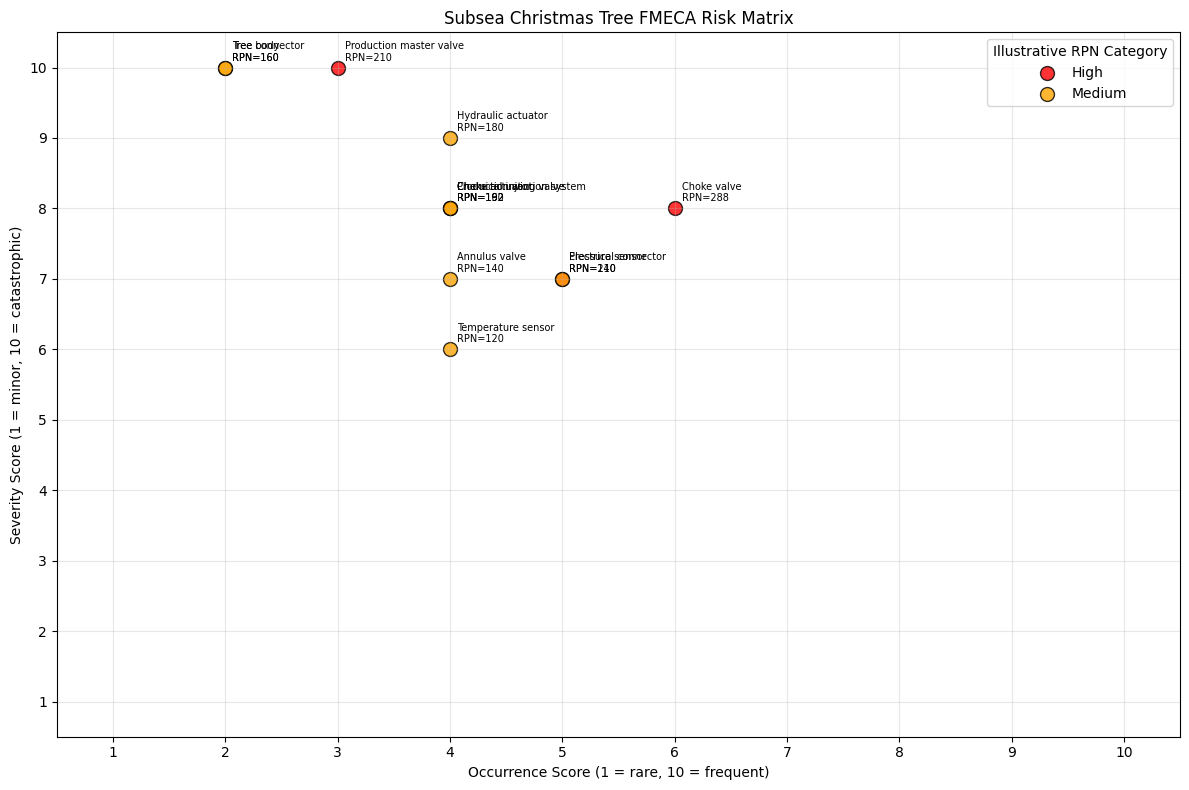

In [4]:

def rpn_category(rpn):
    if rpn >= 200:
        return "High"
    elif rpn >= 100:
        return "Medium"
    return "Low"


fmeca["RPN_category"] = fmeca["RPN"].apply(rpn_category)

risk_colors = {
    "Low": "green",
    "Medium": "orange",
    "High": "red"
}

fig, ax = plt.subplots(figsize=(12, 8))

for category, group in fmeca.groupby("RPN_category"):
    ax.scatter(
        group["occurrence"],
        group["severity"],
        s=100,
        color=risk_colors[category],
        label=category,
        alpha=0.8,
        edgecolors="black"
    )

for _, row in fmeca.iterrows():
    annotation = f'{row["component"]}\nRPN={row["RPN"]}'
    ax.annotate(
        annotation,
        (row["occurrence"], row["severity"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=7
    )

ax.set_xlim(0.5, 10.5)
ax.set_ylim(0.5, 10.5)
ax.set_xticks(range(1, 11))
ax.set_yticks(range(1, 11))
ax.set_xlabel("Occurrence Score (1 = rare, 10 = frequent)")
ax.set_ylabel("Severity Score (1 = minor, 10 = catastrophic)")
ax.set_title("Subsea Christmas Tree FMECA Risk Matrix")
ax.grid(True, alpha=0.3)
ax.legend(title="Illustrative RPN Category")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "fmeca_risk_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


**Final validation and CSV export**

In [5]:

# Validate that the minimum failure-mode requirement is met.
assert len(fmeca) >= 10

# Validate score ranges.
for column in ["severity", "occurrence", "detection"]:
    assert fmeca[column].between(1, 10).all()

# Validate RPN arithmetic.
assert (
    fmeca["RPN"]
    == fmeca["severity"] * fmeca["occurrence"] * fmeca["detection"]
).all()

# Save the final FMECA worksheet.
fmeca.to_csv(
    OUTPUT_DIR / "subsea_christmas_tree_fmeca.csv",
    index=False
)

feature_mapping.to_csv(
    OUTPUT_DIR / "fmeca_physics_ml_feature_mapping.csv",
    index=False
)

print("Case 3 validation passed.")
print(f"Failure modes: {len(fmeca)}")
print("Saved files:")
print(OUTPUT_DIR / "subsea_christmas_tree_fmeca.csv")
print(OUTPUT_DIR / "fmeca_physics_ml_feature_mapping.csv")
print(OUTPUT_DIR / "fmeca_risk_matrix.png")


Case 3 validation passed.
Failure modes: 12
Saved files:
data/subsea_christmas_tree_fmeca.csv
data/fmeca_physics_ml_feature_mapping.csv
data/fmeca_risk_matrix.png
